In [22]:
import os
from PIL import Image
import pandas as pd
import seaborn as seaborn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report


## Vérification nombre d'images de chaque tumeur Training

Ce code permet d'afficher les types de tumeur différentes et le nombre d'images associés à chacune des tumeurs.

In [23]:
liste_tumeur = {}                                                   # On initialise un dictionnaire vide pour stocker chaque tumeurs et le nombre d'images associées

dossier = os.listdir("Dataset/Training")                            # C'est le dossier que l'on va parcourir pour trouver les différentes tumeurs

for k in dossier:                                                   # La boucle qui permet de parcours le dossier pour trouver les différents dossiers relatifs à chaque tumeur
    if k not in liste_tumeur:
        liste_tumeur[k] = 0                                         # On ajoute à la boucle que si elle n'est pas déjà présente dans le dictionnaire

print (f"Liste des différentes tumeurs : {liste_tumeur}") 

for j in liste_tumeur:                                              # On parcourt tout le dictionnaire qui vient d'être rempli 
    dossier_actuel = os.path.join("Dataset/Training", j)            # Les dossiers à parcourir sont donc les différents dossier de tumeurs
    for l in os.listdir(dossier_actuel):
        liste_tumeur[j] += 1                                        # On ajoute 1 à chaque image de chaque tumeurs

print (f"Nombre d'images de chaque tumeur : {liste_tumeur}") 

Liste des différentes tumeurs : {'notumor': 0, 'meningioma': 0, 'pituitary': 0, 'glioma': 0}
Nombre d'images de chaque tumeur : {'notumor': 1400, 'meningioma': 1400, 'pituitary': 1400, 'glioma': 1400}


## Graphique nombre d'image de chaque tumeur Training

On fait un graphique pour bien vérifier qu'il y a le même nombre d'images pour chaque tumeurs.

<Axes: xlabel='Type_Tumeur', ylabel='Count'>

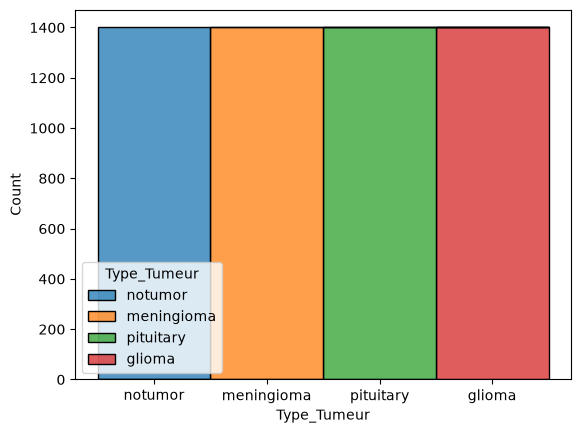

In [24]:
df = pd.DataFrame(list(liste_tumeur.items()), columns=['Type_Tumeur', 'Valeur'])                        # Pour faire un graphique, on transforme le dictionnaire en Dataframe
seaborn.histplot(data=df, x='Type_Tumeur', weights='Valeur', hue='Type_Tumeur', multiple='stack')       # Création du graphique

## Début preprocess (Récupération des infos des images)

Les images de chaque tumeurs ont des paramètres différents. Notre but est de les normaliser afin d'unifier la façon dont on va les traiter et les donner à l'IA pour l'entrainer. 

On va d'abord ce concentrer sur récuperer toutes les images afin d'analyser quels pattern reviennent le plus pour nous permettre de modifier le moins d'images possible. 
On va donc regarder les dimensions les plus présentes, savoir si il y a plus d'image en noir et blanc ou en couleur et enfin le format de compression des images (PNG, JPEG ...) 

In [ ]:
df.head()                                                                   # class de df
df.info()                                                                   # infos du nombre d'entrée du df
df.describe()                                                               # Description df (nombre colonne / infos à l'interieur ...)

liste_taille = {}                                                           # On initialise 3 nouveeux dictionnaires pour les 3 vérifications
liste_format = {}
liste_couleur = {}

for j in liste_tumeur.keys():                                               # On va parcourir les différents dossier de tumeurs et regarder les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        img = Image.open(fichier_actuel)
        if img.size not in liste_taille.keys():                             # Ajout des différentes dimensions des images
            liste_taille[img.size] = 1
        else:
            liste_taille[img.size] += 1
        if img.format not in liste_format.keys():                           # Ajout des différents formats de compression d'image (PNG, JPEG ...)
            liste_format[img.format] = 1
        else:
            liste_format[img.format] += 1 
        if img.mode not in liste_couleur:                                   # Ajout des différent mode de colorimétrie des images (J, RGB, RGBA ...)
            liste_couleur[img.mode] = 1
        else:
            liste_couleur[img.mode] += 1

taille_max = max(liste_taille, key=liste_taille.get)                        # Dimensions les plus présentes
format_max = max(liste_format, key=liste_format.get)                        # Format le plus présent
couleur_max = max(liste_couleur, key=liste_couleur.get)                     # Couleur la plus présente
print ("Type de dimensions : ", liste_taille)
print ("Type de formats : ", liste_format)
print ("Type de couleurs : ", liste_couleur)
print("Dimensions les plus présentes :", str(taille_max) + ". Nombre d'images avec ces dimensions :", liste_taille[taille_max])
print("Format le plus présent :", format_max + ". Nombre d'images avec ce format :", liste_format[format_max])
print("Couleur la plus présente :", couleur_max + ". Nombre d'images avec ce mode de colorimétrie :", liste_couleur[couleur_max])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Type_Tumeur  4 non-null      str  
 1   Valeur       4 non-null      int64
dtypes: int64(1), str(1)
memory usage: 196.0 bytes
Type de dimensions :  {(235, 215): 1, (680, 680): 12, (225, 225): 253, (236, 300): 2, (228, 221): 32, (1024, 1024): 5, (194, 259): 8, (550, 664): 15, (350, 393): 6, (215, 234): 19, (150, 198): 33, (630, 630): 69, (236, 213): 17, (214, 236): 19, (512, 512): 4012, (206, 244): 26, (235, 214): 10, (350, 350): 11, (173, 201): 26, (177, 197): 6, (236, 240): 1, (207, 243): 11, (926, 649): 2, (359, 449): 16, (218, 231): 22, (442, 454): 13, (212, 238): 8, (236, 262): 2, (236, 236): 39, (204, 247): 1, (236, 357): 5, (201, 251): 40, (232, 217): 32, (300, 168): 8, (605, 613): 2, (196, 257): 11, (339, 340): 12, (205, 249): 2, (441, 442): 13, (230, 282): 15, (208, 248): 4, (442, 442): 38, (450, 504): 1, (

## Première conclusion

Tout d'abord, on a bien vérifié qu'il y avait bien le <b>même nombre d'images</b> pour CHAQUE tumeur, et pour les images SANS tumeurs.

On peut le remarquer via les <b>première vérification</b> ainsi que le <u>graphique</u>. Nous avons en tout, <u>5600 images</u>, réparties en <b>4 catégories</b>, ce qui fait 1400 images par catégorie.

Ensuite, nous avons vérifier les <u>différents éléments</u> de chaques images : leurs <b>dimensions</b>, leurs <b>formats</b> et leurs <b>colorimétries.</b>

On a pu voir que sur les <u>5600 images</u>, 4012 était en (512, 512) ce qui va très certainement devenir nos dimensions par défaut. <b>Cependant</b> il faudra faire attention, car certaines images ne sont pas des carrés. Signifiant qu'une conversion sans vérification pourrait applatir ou couper l'image. 

Ensuite, il y en a 5596 en <b>JPEG</b> et 4 en format <b>PNG</b>, bien que noté comme JPEG. Malgré que ces deux formats de compressions soient différents, nous ne trouvons pas cela dérangeant et <u>décidons de ne pas toucher à ces quatres images</u>. Les enlever serai complément contre-productif étant donné qu'elles reste exploitables comme les autres, et peuvent être comparées entre-elles sans difficultés.

Et enfin, leurs colorimétrie. Le plus courant est le <b>RGB</b> avec 3238 images, cependant, malgré qu'elle soit noté comme en <b>RGB</b>, un IRM n'utilise que des nuances de gris, signifiant que la transformation de toutes les images en mode <b>L (Lab / ou CIELLaB)</b> c'est à dire avec des nuances de gris sur une échelle de 0 à 100. 

Pour notre première étape de normalisation, nous décidons donc : 

- <u>De passer toutes les images en noir et blanc.
- De passer toutes les images en dimensions (512, 512)
- De laisser les images avec leurs modes car 99.9% sont en JPEG</u>

## Premier Preprocess

Maintenant que l'on sait vers quoi nous voulons transformer nos images, nous pouvons passer au preprocess.

On va tout d'abord vérifier leurs colorimétrie puis seulement leurs dimensions. 

Pour la colorimétrie, c'est une simple convertion.
Mais pour leurs dimensions, il a fallu distinguer les images carrés des autres. En effet, si un image est carré, alors une simple conversion fera l'affaire. Mais pour une image qui n'est pas carré, la rendre carré va la déformer. C'est pourquoi nous regardons si une image est carré ou non, et si elle ne l'est pas, alors nous la rapprochons le plus des dimensions voulu, puis nous ajoutons des padding pour compléter la taille de l'image.

In [ ]:
X_train = []
y_train = []

for j in liste_tumeur.keys():                                                       # On va reparcourir toutes les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        Dossier_cible = os.path.join("Dataset_clean_512/Training", j)
        img = Image.open(fichier_actuel)
        if img.mode not in ("L", "l"):                                              # Si l'image n'est pas en noir et blanc, alors on la convertit
            img = img.convert('L')

        if img.size != (512, 512):                                                  # Si l'image n'a pas les dimensions (512,512)

            ratio = 512 / max(img.size)                                             # On récupère le ratio par lequel on va diminuer ou augmenter la taille de celle-ci

            nouvelle_taille = (int(img.size[0] * ratio), int(img.size[1] * ratio))  # On définie donc la façon de redimensionner pour s'approcher le plus possible de 512,512

            img = img.resize(nouvelle_taille)                                       # Puis on redimensionne 

            nouvelle_img = Image.new("L", (512, 512))                               # On créer un nouvelle image de taille 512, 512 en nuance de gris, elle va servir d'emplacer du calque de l'image redimensionné

            x = (512 - img.size[0]) // 2                                            # On calcule le niveau de padding nécessaire à ajouter en longueur
            y = (512 - img.size[1]) // 2                                            # Meme chose en largeur

            nouvelle_img.paste(img, (x, y))                                         # Puis la nouvelle image deviens l'image redimenssioner plus le padding (si il y en avait besoin)

            img = nouvelle_img                                                      # On redéfini l'image précédente comme la nouvelle image

            os.makedirs(Dossier_cible, exist_ok=True)                               # On créer le dossier cible s'il n'existait pas
            img.save(os.path.join(Dossier_cible, l))                                # Puis on sauvegarde l'image dans le dossier cible

        else:                                                                       # Si l'image était déjà dans les bonnes dimensions, il suffit simpelemnt de la sauvergarder telle quelle
            os.makedirs(Dossier_cible, exist_ok=True)
            img.save(os.path.join(Dossier_cible, l))
        img_array = np.asarray(img, dtype=np.float32) / 255.0                       # On transforme le vecteur de couleur étant de 0 à 255 sur 0 à 1

        img_array = img_array.flatten()                                             # Transformation de (512, 512) en (262144,)

        X_train.append(img_array)
        y_train.append(j) 

## Vérification formats images

Après avoir tout transformer, on vérifie bien que les dimensions de toutes les images ont bien été transformé en (512, 512).

In [27]:
for j in liste_tumeur.keys():                                               # Vérification que toutes les images sont dans les mêmes formats (dimensions, colorimétrie)
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset_clean/Training", j, l)
        img = Image.open(fichier_actuel)
        print 
        if img.size != (512, 512):
            print("MAUVAISES DIMENSIONS DETECTÉES")

## Vérification des doublons.

In [28]:
# for j in liste_tumeur.keys():
#     dossier_actuel = os.path.join("Dataset/Training", j)
#     fichiers = os.listdir(dossier_actuel)

#     for i in range(len(fichiers)):
#         for k in range(i + 1, len(fichiers)):
#             image_actuelle = os.path.join(dossier_actuel, fichiers[i])
#             image_suivante = os.path.join(dossier_actuel, fichiers[k])

#             img1 = Image.open(image_actuelle)
#             img2 = Image.open(image_suivante)
#     print("yeah")

## Vérification des dimensions

À la fin du preprocess, nous faisons un .flatten() qui "applati" les images qui transforme leurs dimensions (512,512) en (262144,) (512*512 = 262144pixels)

In [29]:
X = np.array(X_train)
y = np.array(y_train)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (5600, 262144)
Dimensions de y : (5600,)


## Modèle KNN

Mainteant que nos données ont été normalisées et vérifiées, nous allons les donner à l'IA pour l'entrainer, pour cela nous utilisons plusieurs modèles afin de trouver lequel est le plus précis.

Ici, nous faisons donc un KNN. Un KNN sert à classer des données ou à prédire une valeur numérique. Et c'est justement ce que l'on veut ici, on veut que notre IA soit capable de classer des images en différentes catégorie de tumeurs.

Le modèle KNN fonctionne de cette manière : 

1) On regarde les données d'entraînement
2) On calcule leur distance par rapport à la nouvelle donnée
3) On sélectionne les K voisins les plus proches
4) On regarde leurs classes
4) On attribue une classe selon les voisins

In [30]:
# random state sert à rendre la séparation reproductible. Sans ça, chaque exécution pourrait produire une séparation différente.
# stratify permet d'éviter que le hasard créer une répartition moins équilibrée
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) 

print("X_train :", X_train_knn.shape)
print("X_test :", X_test_knn.shape)

X_train : (4480, 262144)
X_test : (1120, 262144)


In [31]:
meilleur = 0.0
meilleur_chiffre = 0

for k in range(1, 8, 2):                                        # On teste plusieurs nombre de voisins pour garder le plus efficace
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)                           # On entraine le modèle avec tous les nombres de voisins.

    y_pred = knn.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)
    if accuracy > meilleur:                                     # On récupère le meilleur résultat pour prendre le
        meilleur = accuracy
        meilleur_chiffre = k
        meilleur_y_pred = y_pred
        bon_knn = knn
print(f"Meilleur résultat du KNN via n_neighbors = {meilleur_chiffre} :", meilleur)

Meilleur résultat du KNN via n_neighbors = 1 : 0.9116071428571428


## Matrice de confusion

Afin de voir les résultat de l'IA, pour par exemple voir les différentes erreurs qu'il à pu avoir, nous faison une matrice de confusion. Elle permet de voir la différence entre les résultat qu'il a prédit et les résultats réels.

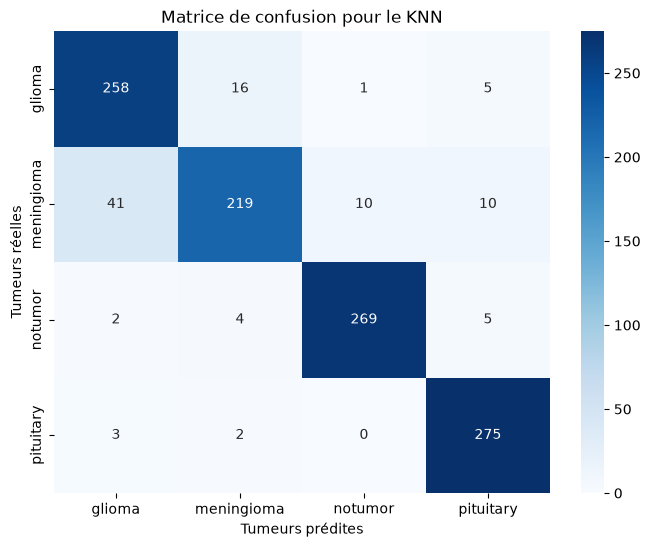

In [32]:

cm = confusion_matrix(y_test_knn, meilleur_y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=bon_knn.classes_, yticklabels=bon_knn.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le KNN")

plt.show()

## Random Forest

Ici, le Random Forest sert à faire des prédictions précises et robustes en combinant plusieurs arbres de décision. Un peu à l'instar du KNN, ce modèle essaye de prédire les catégorie de tumeurs à laquelle les images appartiennent.

In [38]:
# random state sert à rendre la séparation reproductible. Sans ça, chaque exécution pourrait produire une séparation différente.
# n_jobs = -1 permet d'utiliser tous les cœurs CPU disponibles pour les opérations parallélisables.
max_accuracy = 0
bon_n_estimators = 0

for k in range(10, 150, 20):

    randomforest = RandomForestClassifier(n_estimators=k, random_state=42, n_jobs=-1) 

    randomforest.fit(X_train_knn, y_train_knn)

    y_pred = randomforest.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)

    if accuracy > max_accuracy:
        max_accuracy = accuracy
        bon_n_estimators = k
        bon_y_pred = y_pred
        bon_randomforest = randomforest
    print("Résultat du RandomForestClassifier", k, ":", accuracy)


Résultat du RandomForestClassifier 10 : 0.8875
Résultat du RandomForestClassifier 30 : 0.90625
Résultat du RandomForestClassifier 50 : 0.9142857142857143
Résultat du RandomForestClassifier 70 : 0.9151785714285714
Résultat du RandomForestClassifier 90 : 0.9116071428571428
Résultat du RandomForestClassifier 110 : 0.9133928571428571
Résultat du RandomForestClassifier 130 : 0.9151785714285714


## Matrice de confusion

Comme pour le KNN, nous avons fait une matrice de confusion afin de voir les résultats de l'IA. voir les endroits où il a pu se tromper entre ce qu'il à prédit et le véritable résultat.

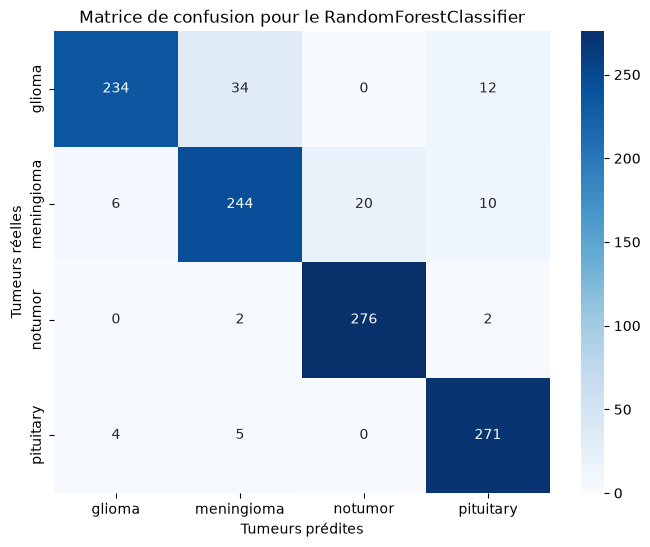

In [39]:
cm = confusion_matrix(y_test_knn, y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=bon_randomforest.classes_, yticklabels=bon_randomforest.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le RandomForestClassifier")

plt.show()

## Modèle LogisticRegression

In [35]:
modele_logreg = LogisticRegression(max_iter=1000, random_state=42) # sert à rendre la séparation reproductible. Sans ça, chaque exécution pourrait produire une séparation différente.
modele_logreg.fit(X_train_knn, y_train_knn)
predictions = modele_logreg.predict(X_test_knn)
precision = accuracy_score(y_test_knn, predictions)

print(f"Précision de la régression logistique : {precision:.4f}")
matrice_confusion = confusion_matrix(y_test_knn, predictions)

Précision de la régression logistique : 0.8268


## Matrice de confusion

Une nouvelle fois, nous avons fait une matrice de confusion afin de voir les résultats de l'IA. voir les endroits où il a pu se tromper entre ce qu'il à prédit et le véritable résultat.

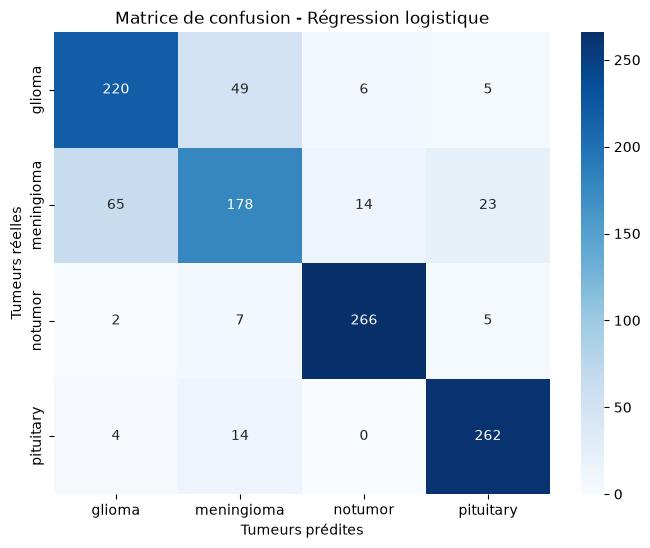

In [36]:
plt.figure(figsize=(8, 6))
seaborn.heatmap(matrice_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=modele_logreg.classes_, yticklabels=modele_logreg.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion - Régression logistique")
plt.show()

## Comparaison des modèles

Maintenant que les quatre modèles ont été entraînés, on peut comparer leurs performances sur les mêmes données de test. Cela permet de voir lequel obtient les meilleurs résultats sur notre jeu de données.

Comparaison des modèles
Accuracy : 0.9116
              precision    recall  f1-score   support

      glioma       0.85      0.92      0.88       280
  meningioma       0.91      0.78      0.84       280
     notumor       0.96      0.96      0.96       280
   pituitary       0.93      0.98      0.96       280

    accuracy                           0.91      1120
   macro avg       0.91      0.91      0.91      1120
weighted avg       0.91      0.91      0.91      1120

Accuracy : 0.9152
              precision    recall  f1-score   support

      glioma       0.96      0.84      0.90       280
  meningioma       0.86      0.87      0.86       280
     notumor       0.94      0.99      0.96       280
   pituitary       0.91      0.96      0.94       280

    accuracy                           0.92      1120
   macro avg       0.92      0.92      0.91      1120
weighted avg       0.92      0.92      0.91      1120

Accuracy : 0.8268
              precision    recall  f1-score   suppor

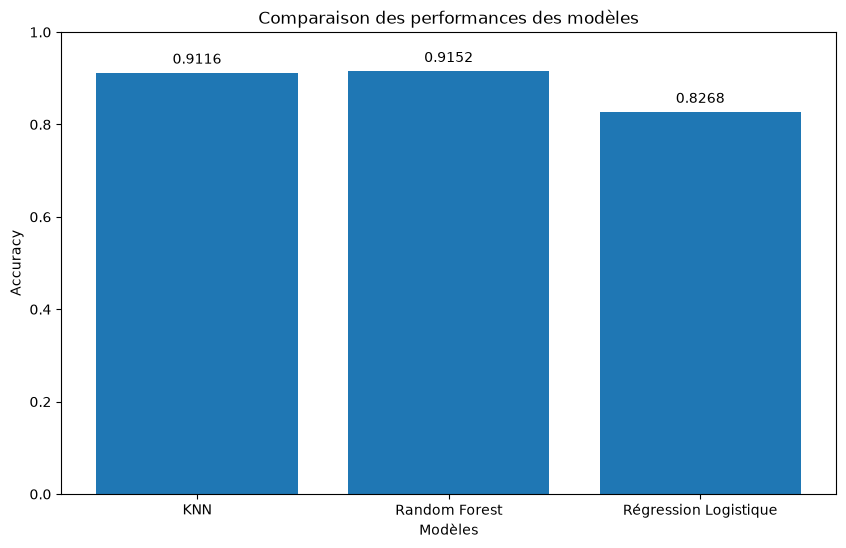

Resultats de la comparaison
Le modèle avec la plus grande accuracy dans ce test est : Random Forest (0.9152)


In [40]:
modeles = {"KNN": bon_knn, "Random Forest": bon_randomforest, "Régression Logistique": modele_logreg}
resultats = {}

print("Comparaison des modèles")

for nom, modele in modeles.items():
    predictions = modele.predict(X_test_knn)
    accuracy = accuracy_score(y_test_knn, predictions)
    resultats[nom] = accuracy
    print(f"Accuracy : {accuracy:.4f}")
    print(classification_report(y_test_knn, predictions))


# Matrice de confusion pour chaque modèle
print("Performance des modèles :")

for nom, accuracy in resultats.items():
    print(f"{nom:<25} : {accuracy:.4f}")


# Comparaison des modèles
plt.figure(figsize=(10, 6))
plt.bar(resultats.keys(), resultats.values())

plt.xlabel("Modèles")
plt.ylabel("Accuracy")
plt.title("Comparaison des performances des modèles")
plt.ylim(0, 1)

# Affichage de la valeur au-dessus de chaque barre
for i, (nom, accuracy) in enumerate(resultats.items()):
    plt.text(i, accuracy + 0.02, f"{accuracy:.4f}", ha="center")
plt.show()


# modèle avec + d'accuracy
meilleur_modele = max(resultats, key=resultats.get)

print("Resultats de la comparaison")
print(f"Le modèle avec la plus grande accuracy dans ce test est : "f"{meilleur_modele} ({resultats[meilleur_modele]:.4f})")
